In [8]:
import time
import pandas as pd
from gdeltdoc import GdeltDoc, Filters

gd=GdeltDoc()

f= Filters(
    keyword="guvern",
    country="RO",
    start_date="2026-09-20",
    end_date="2026-10-10",
    num_records=250,
)

articles=gd.article_search(f)
print("Articole:",len(articles))
print(articles.columns.tolist())
articles.head

RateLimitError: 

In [10]:
import requests

def gdelt_raw(query):
    url = "https://api.gdeltproject.org/api/v2/doc/doc"
    params = {
        "query": query,
        "mode": "artlist",
        "format": "json",
        "maxrecords": 50,
        "startdatetime": "20260920000000",
        "enddatetime": "20261010000000",
    }
    resp = requests.get(url, params=params, timeout=60)
    print("Query:", query)
    print("Status:", resp.status_code)
    print(resp.text[:300])
    print("-" * 60)

gdelt_raw("guvern sourcecountry:RO")
time.sleep(10)
gdelt_raw("government sourcecountry:RO")
time.sleep(10)
gdelt_raw("Romania government")

Query: guvern sourcecountry:RO
Status: 429
Please limit requests to one every 5 seconds or contact kalev.leetaru5@gmail.com for larger queries. All high-traffic users should switch to our ngrams dataset: https://blog.gdeltproject.org/using-the-new-web-ngrams-dataset-to-find-relevant-coverage/. For trend analysis, please see our daily newslet
------------------------------------------------------------
Query: government sourcecountry:RO
Status: 429
Please limit requests to one every 5 seconds or contact kalev.leetaru5@gmail.com for larger queries. All high-traffic users should switch to our ngrams dataset: https://blog.gdeltproject.org/using-the-new-web-ngrams-dataset-to-find-relevant-coverage/. For trend analysis, please see our daily newslet
------------------------------------------------------------
Query: Romania government
Status: 429
Please limit requests to one every 5 seconds or contact kalev.leetaru5@gmail.com for larger queries. All high-traffic users should switch to our ngr

In [1]:
import time
import feedparser
import pandas as pd
from urllib.parse import quote

def gnews(query, start, end):
    q = f"{query} after:{start} before:{end}"
    url = f"https://news.google.com/rss/search?q={quote(q)}&hl=ro&gl=RO&ceid=RO:ro"
    feed = feedparser.parse(url)
    rows = [{
        "published": e.get("published", ""),
        "source": e.get("source", {}).get("title", "?"),
        "title": e.get("title", ""),
    } for e in feed.entries]
    df = pd.DataFrame(rows)
    if len(df) > 0:
        df["published"] = pd.to_datetime(df["published"], utc=True, format="%a, %d %b %Y %H:%M:%S GMT")
    return df

start, end = "2025-05-01", "2025-06-01"
tests = [
    'alegeri prezidențiale',
    '"alegeri prezidențiale"',
    '"moțiune de cenzură"',
    '"alegeri prezidențiale" OR "moțiune de cenzură"',
    'România ("alegeri prezidențiale" OR "moțiune de cenzură")',
]
for q in tests:
    df = gnews(q, start, end)
    print(f"{len(df):4d}  {q}")
    time.sleep(5)


 100  alegeri prezidențiale
 100  "alegeri prezidențiale"
  16  "moțiune de cenzură"
 100  "alegeri prezidențiale" OR "moțiune de cenzură"
  49  România ("alegeri prezidențiale" OR "moțiune de cenzură")


2015 25
2016 41
2017 39
2018 30
2019 45
2020 45
2021 45
2022 47
2023 49
2024 45
2025 48
2026 68


<Axes: title={'center': "Articole Google News - 'guvern România', luna martie a fiecarui an"}, xlabel='an'>

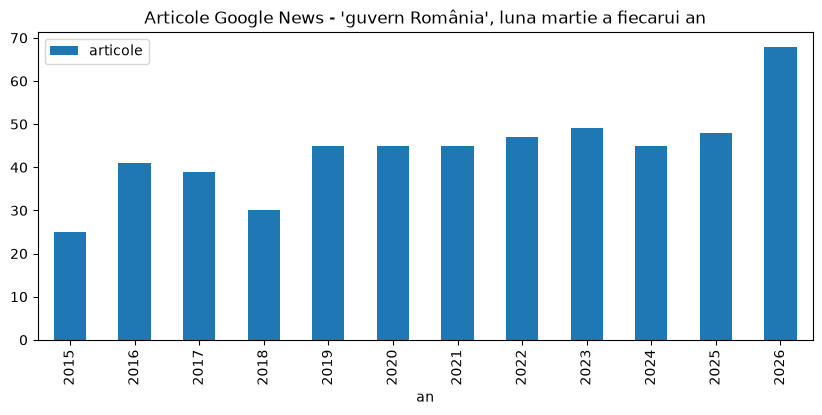

In [13]:
coverage = []
for year in range(2015, 2027):
    df = gnews("guvern România", f"{year}-03-01", f"{year}-03-31")
    coverage.append({"an": year, "articole": len(df),
                     "surse": df["source"].nunique() if len(df) else 0})
    print(year, len(df))
    time.sleep(5)

coverage = pd.DataFrame(coverage)
coverage.plot(x="an", y="articole", kind="bar", figsize=(10, 4),
              title="Articole Google News - 'guvern România', luna martie a fiecarui an")

In [2]:
h = pd.read_csv("../data/news_history.csv")
h["published"] = pd.to_datetime(h["published"], utc=True, format="%a, %d %b %Y %H:%M:%S GMT")

p = h[h["category"] == "politic"]
u = p.drop_duplicates(subset="link")

print("Randuri:", len(p), "| Articole unice:", len(u))
print("Interval:", u["published"].min().date(), "->", u["published"].max().date())
print()
print(u.groupby(u["published"].dt.date).size().to_string())

Randuri: 3100 | Articole unice: 141
Interval: 2026-06-19 -> 2026-10-14

published
2026-06-19     1
2026-07-16     1
2026-07-17     1
2026-07-30     1
2026-08-04     1
2026-08-30     2
2026-09-18     1
2026-09-21     1
2026-09-23     1
2026-09-25     6
2026-09-26     1
2026-09-28     2
2026-09-29     3
2026-09-30     4
2026-10-01     1
2026-10-02     2
2026-10-04     2
2026-10-05     6
2026-10-06     4
2026-10-07     9
2026-10-08     2
2026-10-09     4
2026-10-10     2
2026-10-11     2
2026-10-12    42
2026-10-13    32
2026-10-14     7


In [3]:
u.sample(15, random_state=1)[["published", "source", "title"]]

,published,source,title
78,2026-10-12 09:51:14+00:00,Mediafax,Surse. PNL ia în calcul să nu depună moțiune d...
582,2026-09-26 07:00:00+00:00,RFI,AEP pregătește reguli pentru alegeri anticipat...
31,2026-10-12 20:12:02+00:00,Ziare.com,Alina Gorghiu anticipează un eșec pentru liber...
5,2026-10-14 06:24:00+00:00,Spotmedia.ro,Președintele care a ales greșit - Spotmedia.ro
591,2026-10-13 18:44:10+00:00,Informat.ro,Sorin Grindeanu spune că anticipatele nu sunt ...
45,2026-10-12 22:42:32+00:00,Monitorul de Vrancea,Grindeanu: PSD e pregătit de alegeri anticipat...
14,2026-10-11 18:08:00+00:00,www.goldring.ro,Rareș Bogdan: Președintele va fi forțat să org...
44,2026-10-06 13:21:42+00:00,Digi24,AUR respinge susținerea Guvernului Niculescu. ...
73,2026-10-01 07:00:00+00:00,Agerpres,Republica Cehă: Premierul scapă de o moțiune d...
89,2026-10-06 01:00:38+00:00,www.goldring.ro,Luca Niculescu desemnat premier: PSD avertizea...


In [4]:
q = "criză politică"
for start, end in [("2025-05-01", "2025-06-01"),
                   ("2025-05-01", "2025-05-16"),
                   ("2025-05-16", "2025-06-01")]:
    df = gnews(q, start, end)
    print(f"{start} -> {end}: {len(df)} articole")
    time.sleep(5)

2025-05-01 -> 2025-06-01: 47 articole
2025-05-01 -> 2025-05-16: 42 articole
2025-05-16 -> 2025-06-01: 47 articole
